In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving prediction_traffic_lstm_feature_engineering.csv to prediction_traffic_lstm_feature_engineering.csv


In [ ]:
df_clean = pd.read_csv("prediction_traffic_lstm_feature_engineering.csv")

# to convert the string and set as index
df_clean['date_time'] = pd.to_datetime(df_clean['date_time'])
df_clean = df_clean.set_index('date_time').sort_index()

In [ ]:
val_start = df_clean.index.get_loc("2016-10-01 09:00:00")
test_start = df_clean.index.get_loc("2017-10-02 09:00:00")
n = len(df_clean)

print(f"Validation data starts at: {val_start}")
print(f"Testing data starts at: {test_start}")
print(f"Total number of data: {n}")

Validation data starts at: 23168
Testing data starts at: 31875
Total number of data: 40575


In [ ]:
target_column = "traffic_volume"
feature_columns = [col for col in df_clean.columns if col not in ["traffic_volume", "date_time"]]

In [ ]:
# Splitting data
train = df_clean.iloc[:val_start]
val = df_clean.iloc[val_start: test_start]
test = df_clean.iloc[test_start: n]

X_train, y_train = train[feature_columns].to_numpy(), train[target_column].to_numpy()
X_val, y_val = val[feature_columns].to_numpy(), val[target_column].to_numpy()
X_test, y_test = test[feature_columns].to_numpy(), test[target_column].to_numpy()

In [ ]:
# Scaling using min-max scaler
from sklearn.preprocessing import MinMaxScaler

scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

# for y -> it is in 1D, but min-max need 2D

X_train_scaled = scaler_X.fit_transform(X_train)
y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1))

X_val_scaled = scaler_X.transform(X_val)
y_val_scaled = scaler_y.transform(y_val.reshape(-1, 1))

X_test_scaled = scaler_X.transform(X_test)
y_test_scaled = scaler_y.transform(y_test.reshape(-1, 1))

In [ ]:
# Let model refers to the last 24 hours
SEQ_LENGTH = 24

In [ ]:
def make_sequence(X, y, seq_length):
  Xs = []
  ys = []

  for i in range(seq_length, len(X)):
    Xs.append(X[i - seq_length: i])
    ys.append(y[i])

  return np.array(Xs), np.array(ys)

In [ ]:
X_train_seq, y_train_seq = make_sequence(X_train_scaled, y_train_scaled, SEQ_LENGTH)
X_val_seq, y_val_seq = make_sequence(X_val_scaled, y_val_scaled, SEQ_LENGTH)
X_test_seq, y_test_seq = make_sequence(X_test_scaled, y_test_scaled, SEQ_LENGTH)

In [ ]:
print(f"Train: {X_train_seq.shape}, {y_train_seq.shape}")
print(f"Validation: {X_val_seq.shape}, {y_val_seq.shape}")
print(f"Test: {X_test_seq.shape}, {y_test_seq.shape}")

Train: (23144, 24, 30), (23144, 1)
Validation: (8683, 24, 30), (8683, 1)
Test: (8676, 24, 30), (8676, 1)


In [ ]:
model = xgb.XGBRegressor(
    objective = "reg:squarederror",
    n_estimators = 200,
    learning_rate = 0.1,
    max_depth = 5,
    random_state = 42,
    eval_metric = "mae"
)

In [ ]:
model.fit(
    X_train_seq.reshape(X_train_seq.shape[0], -1), y_train_seq,
    eval_set = [(X_val_seq.reshape(X_val_seq.shape[0], -1), y_val_seq)]
)

[0]	validation_0-mae:0.21511
[1]	validation_0-mae:0.19535
[2]	validation_0-mae:0.17773
[3]	validation_0-mae:0.16210
[4]	validation_0-mae:0.14826
[5]	validation_0-mae:0.13570
[6]	validation_0-mae:0.12462
[7]	validation_0-mae:0.11483
[8]	validation_0-mae:0.10606
[9]	validation_0-mae:0.09849
[10]	validation_0-mae:0.09184
[11]	validation_0-mae:0.08571
[12]	validation_0-mae:0.08041
[13]	validation_0-mae:0.07559
[14]	validation_0-mae:0.07132
[15]	validation_0-mae:0.06768
[16]	validation_0-mae:0.06456
[17]	validation_0-mae:0.06169
[18]	validation_0-mae:0.05912
[19]	validation_0-mae:0.05680
[20]	validation_0-mae:0.05485
[21]	validation_0-mae:0.05303
[22]	validation_0-mae:0.05150
[23]	validation_0-mae:0.05003
[24]	validation_0-mae:0.04870
[25]	validation_0-mae:0.04774
[26]	validation_0-mae:0.04705
[27]	validation_0-mae:0.04637
[28]	validation_0-mae:0.04550
[29]	validation_0-mae:0.04447
[30]	validation_0-mae:0.04372
[31]	validation_0-mae:0.04298
[32]	validation_0-mae:0.04267
[33]	validation_0-ma

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric='mae', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=200,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
# Predict scaled values
y_pred_scaled = model.predict(X_test_seq.reshape(X_test_seq.shape[0], -1))

# Inverse scale back to real traffic volume
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1))
y_actual = scaler_y.inverse_transform(y_test_seq)

print("Predictions shape:", y_pred.shape)

Predictions shape: (8676, 1)


In [ ]:
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
mae = mean_absolute_error(y_actual, y_pred)
mape = mean_absolute_percentage_error(y_actual, y_pred)
r2 = r2_score(y_actual, y_pred)

print(f"RMSE: {rmse:.5f}")
print(f"MAE: {mae:.5f}")
print(f"MAPE: {mape:.5f}")
print(f"R2 Score: {r2:.5f}")

RMSE: 412.65267
MAE: 266.66860
MAPE: 0.11779
R2 Score: 0.95642


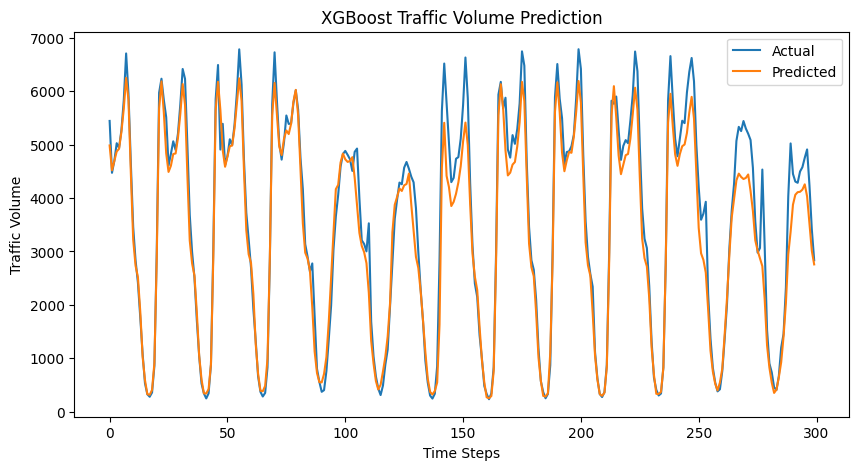

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(y_actual[:300], label='Actual')
plt.plot(y_pred[:300], label='Predicted')
plt.title('XGBoost Traffic Volume Prediction')
plt.xlabel('Time Steps')
plt.ylabel('Traffic Volume')
plt.legend()
plt.show()

In [ ]:
model.save_model('xgboost_traffic.json')